# Q006: Neuromorphic Classification with Linear Wave Scattering, Under Noise

## Problem
In **Q003** we asked how much hardware noise a QAOA circuit can survive. Here we ask the same question of a different kind of machine: one that *computes with waves*.

A network of 64 coupled resonators is probed with light at one port. Each pixel of an 8×8 handwritten digit sets the **detuning** of one resonator, and the light that comes out at ten output ports is the class score. The scattering problem is **linear**, yet the output depends *nonlinearly* on the input, because the scattering matrix $S = 1 - i\kappa G$ contains the inverse $G = (\omega - H + i\Gamma/2)^{-1}$ and $H$ contains the input.

This follows the idea of Wanjura & Marquardt, *Fully nonlinear neuromorphic computing with linear wave scattering*, Nature Physics **20**, 1434 (2024).

1. Can such a network classify digits, and how does it compare with a logistic regression and a small MLP?
2. How does accuracy fall when the resonator detunings are noisy (a stand-in for fabrication error or drift)?
3. Does training *with* noise help?

*Simplifications compared with the paper:* fully connected couplings, one probe port, no racetrack-resonator layout. Results are small-scale and use 5 training seeds.

In [1]:
!pip install -q jax scikit-learn matplotlib

## 1. Setup: data and physical parameters
One resonator per pixel. Port 0 is the probe; ports 1–10 are the digits 0–9. $\alpha$ sets how strongly a pixel detunes its resonator, so the full input range is $\alpha = 2$.

In [2]:
import argparse, pickle, time
import numpy as np, jax, jax.numpy as jnp
import sys, matplotlib
IN_NOTEBOOK = "ipykernel" in sys.modules                # Jupyter / Colab / Kaggle
if not IN_NOTEBOOK: matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier

jax.config.update("jax_enable_x64", True)

d = load_digits(); X = d.data / 16.0; y = d.target
_rng = np.random.default_rng(0); _idx = _rng.permutation(len(X)); ntr = int(0.75 * len(X))
Xtr, ytr, Xte, yte = X[_idx[:ntr]], y[_idx[:ntr]], X[_idx[ntr:]], y[_idx[ntr:]]
N = 64                                                    # one resonator per pixel
ports = np.linspace(0, N - 1, 11).astype(int)             # ports[0] = probe, ports[1:] = digits 0..9
OMEGA, GAMMA, KAPPA, ALPHA = 0.0, 0.1, 0.5, 2.0           # probe frequency, internal loss, port coupling, input scale
pmask = np.zeros(N); pmask[ports] = 1.0
NOISE_LEVELS = [0.0, 0.05, 0.1, 0.2, 0.4]                 # detuning noise sigma (full input range = ALPHA)

## 2. The model
`_system` solves the linear scattering problem for a batch of digits and returns the field in every resonator. The class logits are the output-port intensities $|S_{p0}|^2$, scaled by a trainable factor. Trainable: couplings $C$, detuning offsets $b$, a scale and a bias.

In [3]:
def _system(params, x, sigma, key):
    C = (params["C"] + params["C"].T) / 2; C = C - jnp.diag(jnp.diag(C))
    det = params["b"][None, :] + ALPHA * x + sigma * jax.random.normal(key, x.shape)
    A = (OMEGA + 0.5j * GAMMA) * jnp.eye(N)[None] - (C[None] + jax.vmap(jnp.diag)(det)) \
        + 0.5j * KAPPA * jnp.diag(pmask)[None]
    e = jnp.zeros(N, dtype=complex).at[ports[0]].set(1.0)
    return jnp.linalg.solve(A, jnp.broadcast_to(e, (x.shape[0], N))[..., None])[..., 0]   # field g at every resonator

def forward(params, x, sigma=0.0, key=jax.random.PRNGKey(0)):
    g = _system(params, x, sigma, key)
    return params["s"] * jnp.abs(KAPPA * g[:, ports[1:]]) ** 2 + params["c"]                 # class logits

def loss(params, x, yy, sigma=0.0, key=jax.random.PRNGKey(0)):
    lg = forward(params, x, sigma, key); lg = lg - jax.nn.logsumexp(lg, axis=1, keepdims=True)
    return -jnp.mean(lg[jnp.arange(len(yy)), yy])

def acc(params, x, yy, sigma=0.0, key=jax.random.PRNGKey(0)):
    return float(jnp.mean(jnp.argmax(forward(params, x, sigma, key), 1) == yy))

def train(sigma_train=0.0, steps=500, bs=256, lr=0.02, seed=0):
    k = jax.random.PRNGKey(seed)
    params = {"C": 0.05 * jax.random.normal(k, (N, N)), "b": jnp.zeros(N), "s": jnp.array(20.0), "c": jnp.zeros(10)}
    m = jax.tree_util.tree_map(jnp.zeros_like, params); v = jax.tree_util.tree_map(jnp.zeros_like, params)
    gfun = jax.jit(jax.value_and_grad(loss)); r = np.random.default_rng(seed)
    for t in range(1, steps + 1):                                                    # Adam
        b = r.choice(ntr, bs, replace=False); k, sk = jax.random.split(k)
        _, g = gfun(params, jnp.array(Xtr[b]), jnp.array(ytr[b]), sigma_train, sk)
        m = jax.tree_util.tree_map(lambda m_, g_: 0.9 * m_ + 0.1 * g_, m, g)
        v = jax.tree_util.tree_map(lambda v_, g_: 0.999 * v_ + 0.001 * g_ ** 2, v, g)
        params = jax.tree_util.tree_map(
            lambda p, m_, v_: p - lr * (m_ / (1 - 0.9 ** t)) / (jnp.sqrt(v_ / (1 - 0.999 ** t)) + 1e-8), params, m, v)
    return params

## 3. Experiment
For each of 5 seeds we train one network without noise and one with Gaussian noise (σ = 0.1) added to the detunings, then test both at five noise levels, averaging over 5 noise draws. Logistic regression and a 32-unit MLP give reference accuracies.

In [4]:
def run_experiment(n_seeds):
    Xt, yt = jnp.array(Xte), jnp.array(yte)
    res = {"sigma": NOISE_LEVELS, "clean": [], "noisy": [], "params": {}}; t0 = time.time()
    for s in range(n_seeds):
        for tag, st in [("clean", 0.0), ("noisy", 0.1)]:
            p = train(st, seed=s * 10 + (1 if tag == "noisy" else 0))
            row = [np.mean([acc(p, Xt, yt, sg, jax.random.PRNGKey(i)) for i in range(5)]) for sg in NOISE_LEVELS]
            res[tag].append(row)
            if s == 0: res["params"][tag] = jax.tree_util.tree_map(np.array, p)
            print(f"seed {s} {tag:5s}: {np.round(row, 3)}  ({time.time() - t0:.0f}s)", flush=True)
    res["lr"] = LogisticRegression(max_iter=2000).fit(Xtr, ytr).score(Xte, yte) * 100
    res["mlp"] = MLPClassifier((32,), max_iter=800, random_state=0).fit(Xtr, ytr).score(Xte, yte) * 100
    return res

## 4. Figures
Plot helpers (palette: blue and orange for the two trained networks, gray for baselines).

In [5]:
BG, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"          # surface and ink
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#8a8984"                       # categorical slots 1, 2; neutral for baselines
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG, "text.color": INK,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 11})
SEQ = LinearSegmentedColormap.from_list("seq", ["#f1f6fc", BLUE, "#0b2a52"])
DIV = LinearSegmentedColormap.from_list("div", [ORANGE, "#ececea", BLUE])

def _finish(fig, path):
    fig.savefig(path, dpi=160)
    plt.show() if IN_NOTEBOOK else plt.close(fig)

def fig_anatomy(P, path):
    digits = [0, 3, 7, 8]; pick = [int(np.where(yte == dd)[0][0]) for dd in digits]; xs = jnp.array(Xte[pick])
    g = _system(P, xs, 0.0, jax.random.PRNGKey(0)); F = np.array(jnp.abs(g) ** 2)
    I = np.array(jnp.abs(KAPPA * g[:, ports[1:]]) ** 2); pred = np.array(forward(P, xs)).argmax(1)
    fig, ax = plt.subplots(3, 4, figsize=(10.5, 8.2), gridspec_kw={"height_ratios": [1, 1, 0.9]})
    for k in range(4):
        ax[0, k].imshow(Xte[pick[k]].reshape(8, 8), cmap="Greys", vmin=0, vmax=1); ax[0, k].set_title(f"input: a '{digits[k]}'")
        ax[1, k].imshow(np.log10(F[k]).reshape(8, 8), cmap=SEQ)
        ax[1, k].set_title("light in each resonator (log)", fontsize=9, fontweight="normal", color=INK2)
        cols = [GRAY] * 10; cols[digits[k]] = BLUE
        ax[2, k].bar(range(10), I[k] / I[k].sum(), color=cols, width=0.7)
        ax[2, k].set_xticks(range(10)); ax[2, k].set_ylim(0, 1); ax[2, k].set_xlabel("output port = digit")
        ax[2, k].set_title(f"predicted: {pred[k]}", fontsize=10)
        for a in ax[:2, k]: a.set_xticks([]); a.set_yticks([])
        ax[2, k].grid(axis="y", color=GRID, lw=0.6); ax[2, k].set_axisbelow(True)
    ax[2, 0].set_ylabel("share of output light")
    fig.suptitle("Q006: a linear wave network reads a digit from where the light goes\n"
                 "probe light enters one port; each pixel detunes one resonator; middle row: darker blue = more light; blue bar = correct digit",
                 y=0.995, fontsize=11.5, fontweight="bold")
    fig.tight_layout(); _finish(fig, path)

def fig_learned(P, path):
    C = np.array((P["C"] + P["C"].T) / 2); np.fill_diagonal(C, 0)
    fig, ax = plt.subplots(1, 3, figsize=(11.5, 3.9))
    lim = np.percentile(np.abs(C), 99); im = ax[0].imshow(C, cmap=DIV, norm=TwoSlopeNorm(0, -lim, lim))
    ax[0].set_title("learned couplings between resonators"); ax[0].set_xlabel("resonator"); ax[0].set_ylabel("resonator")
    plt.colorbar(im, ax=ax[0], fraction=0.046)
    b = np.array(P["b"]).reshape(8, 8); l2 = np.abs(b).max()
    im = ax[1].imshow(b, cmap=DIV, norm=TwoSlopeNorm(0, -l2, l2)); ax[1].set_title("learned detuning offset per pixel")
    ax[1].set_xticks([]); ax[1].set_yticks([]); plt.colorbar(im, ax=ax[1], fraction=0.046)
    pr = np.array(forward(P, jnp.array(Xte))).argmax(1); cm = np.zeros((10, 10))
    for t, p_ in zip(yte, pr): cm[t, p_] += 1
    im = ax[2].imshow(cm / cm.sum(1, keepdims=True), cmap=SEQ, vmin=0, vmax=1)
    ax[2].set_title(f"test confusion (accuracy {np.trace(cm) / cm.sum():.1%})")
    ax[2].set_xlabel("predicted digit"); ax[2].set_ylabel("true digit"); ax[2].set_xticks(range(10)); ax[2].set_yticks(range(10))
    plt.colorbar(im, ax=ax[2], fraction=0.046)
    fig.tight_layout(); _finish(fig, path)

def fig_noise(res, path):
    sg = np.array(res["sigma"]); n_seeds = len(res["clean"])
    fig, ax = plt.subplots(figsize=(7.4, 4.6)); xs = np.arange(len(sg))
    for arr, c, lab in [(np.array(res["clean"]) * 100, BLUE, "trained without noise"),
                        (np.array(res["noisy"]) * 100, ORANGE, "trained with noise (σ = 0.1)")]:
        m, s = arr.mean(0), arr.std(0)
        ax.fill_between(xs, m - s, m + s, color=c, alpha=0.16, lw=0)
        ax.plot(xs, m, color=c, lw=2, marker="o", ms=6, mec=BG, mew=2, label=lab)
    for v, lab, dy, va in [(res["lr"], f"logistic regression {res['lr']:.1f}%", -0.5, "top"),
                           (res["mlp"], f"MLP (32 hidden units) {res['mlp']:.1f}%", 0.5, "bottom")]:
        ax.axhline(v, color=GRAY, ls=(0, (5, 4)), lw=1.2); ax.text(len(sg) - 1.0, v + dy, lab, color=INK2, ha="right", va=va, fontsize=9)
    ax.set_xticks(xs); ax.set_xticklabels([f"{s:g}" for s in sg]); ax.set_ylim(70, 100)
    ax.set_xlabel(f"noise on resonator detunings, σ  (full input range = {ALPHA:g})"); ax.set_ylabel("test accuracy (%)")
    ax.grid(axis="y", color=GRID, lw=0.6); ax.set_axisbelow(True); ax.legend(frameon=False, loc="lower left")
    ax.set_title(f"Accuracy survives modest detuning noise\nmean ± s.d. over {n_seeds} training seeds")
    fig.tight_layout(); _finish(fig, path)

## 5. Run it
About 4–5 minutes on two CPU cores. Use `n_seeds = 2` for a quick check.

In [6]:
n_seeds = 5
res = run_experiment(n_seeds)

seed 0 clean: [0.96  0.959 0.956 0.926 0.758]  (31s)


seed 0 noisy: [0.962 0.964 0.963 0.944 0.796]  (59s)


seed 1 clean: [0.964 0.965 0.96  0.935 0.756]  (85s)


seed 1 noisy: [0.962 0.964 0.959 0.931 0.789]  (112s)


seed 2 clean: [0.971 0.972 0.962 0.937 0.743]  (139s)


seed 2 noisy: [0.973 0.964 0.964 0.949 0.805]  (165s)


seed 3 clean: [0.949 0.945 0.938 0.909 0.741]  (190s)


seed 3 noisy: [0.969 0.963 0.96  0.94  0.797]  (216s)


seed 4 clean: [0.958 0.958 0.954 0.933 0.738]  (242s)


seed 4 noisy: [0.944 0.943 0.94  0.924 0.788]  (268s)


### How one classification works
Probe light enters one port. The middle row shows how much light ends up in each resonator (darker = more); the bottom row shows where the light leaves. The blue bar is the correct digit.

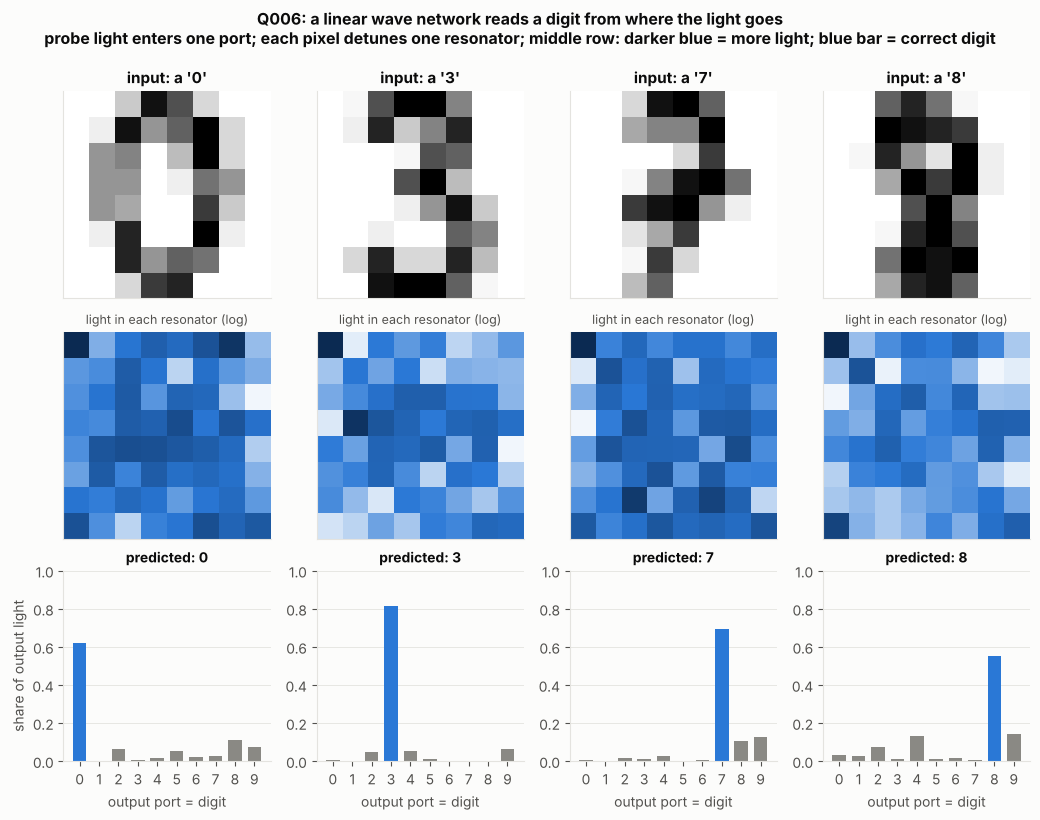

In [7]:
fig_anatomy(res["params"]["clean"], "q006_fig1_anatomy.png")

### What was learned
Couplings, detuning offsets, and the test confusion matrix of the first clean-trained network.

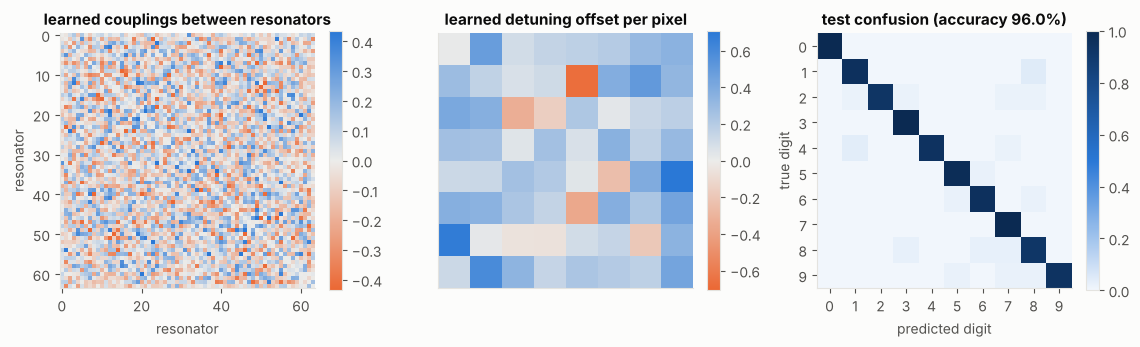

In [8]:
fig_learned(res["params"]["clean"], "q006_fig2_learned.png")

### Robustness to detuning noise

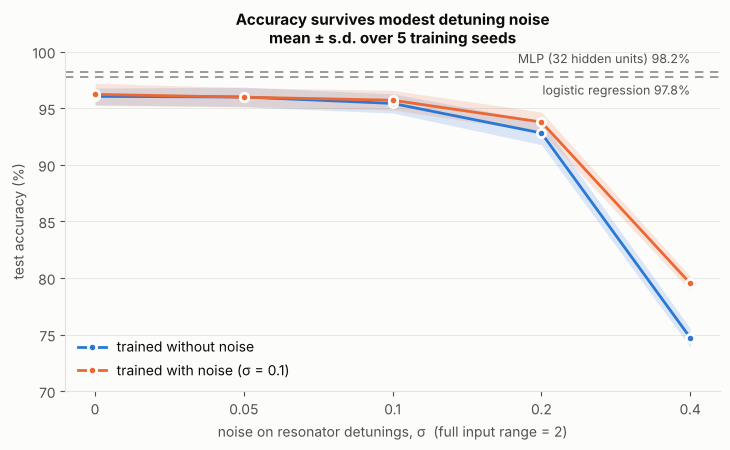

sigma          [0.0, 0.05, 0.1, 0.2, 0.4]
clean-trained  [96.  96.  95.4 92.8 74.7] +/- [0.7 0.9 0.8 1.  0.8]
noise-trained  [96.2 96.  95.7 93.8 79.5] +/- [1.  0.8 0.9 0.9 0.6]
logistic regression 97.8%   MLP 98.2%


In [9]:
fig_noise(res, "q006_fig3_noise.png")

cl, no = np.array(res["clean"]) * 100, np.array(res["noisy"]) * 100
print("sigma         ", NOISE_LEVELS)
print("clean-trained ", cl.mean(0).round(1), "+/-", cl.std(0).round(1))
print("noise-trained ", no.mean(0).round(1), "+/-", no.std(0).round(1))
print(f"logistic regression {res['lr']:.1f}%   MLP {res['mlp']:.1f}%")

## Solution and discussion

**1. It works, but it does not beat a plain linear classifier.** A purely linear wave system reaches about **96%** test accuracy on 8×8 digits. Logistic regression reaches 97.8% and a small MLP 98.2%. The paper's reported advantage over a "linear network" does not appear here, because their linear baseline is a restricted one and mine is a full logistic regression on raw pixels.

**2. Robust to modest detuning noise.** Accuracy is essentially unchanged up to σ = 0.1 (about 5% of the full input range) and is still about 93% at σ = 0.2. It collapses toward 75% at σ = 0.4 (20% of full scale).

**3. Training with noise helps only when the noise is large.** At σ = 0.4 the noise-trained networks are about 5 points better (79.5% vs 74.7%), several standard deviations across 5 seeds. At σ = 0.2 the gain is about 1 point, roughly one standard deviation, so it is not convincing. At low noise the two are indistinguishable.

**4. The learned couplings show no obvious structure** (figure 2). Nothing here shows what the network "found".

*Caveats:* the test set has 450 samples, so each accuracy carries about ±1% sampling error on top of the seed spread. Only one architecture and one probe frequency were tried.

*Try next:* a layered architecture closer to the paper, a restricted linear baseline, several probe frequencies, and noise on the couplings as well as the detunings.